<div style="background:linear-gradient(135deg,#1b1448 0%,#3b1f5e 55%,#7c2d12 100%);border-radius:18px;padding:34px 30px;color:#fff;font-family:Inter,Segoe UI,sans-serif">
  <div style="font-size:12px;letter-spacing:3px;color:#fed7aa;font-weight:700;text-transform:uppercase">Chapter 2 · How a language model produces text</div>
  <div style="font-size:34px;font-weight:900;line-height:1.1;margin:10px 0 6px">How a language model produces text</div>
  <div style="font-size:15px;color:#ffe4d6;max-width:740px;line-height:1.6">Tokens, the probabilities a model assigns to its next token, and what sampling looks like from outside the model, measured on repeated calls.</div>
  <div style="font-size:13px;color:#fed7aa;margin-top:14px">Building AI with AI: A Visual Handbook · John Fisher</div>
</div>

A language model generates text one token at a time. At each step it assigns a probability to every token in its vocabulary, samples one, appends it to the text and repeats. This notebook measures what can be measured from outside the model: how text splits into tokens, how scores become probabilities, and how the answers to one request spread when it is sent many times.

## Setup

This cell installs Anthropic's Python library and builds the client every call below goes through. It replays recorded answers unless you set `LIVE = True`.

In [1]:
# Set LIVE = True to send these requests to the Anthropic API with your own key, saved in
# Colab's secrets panel as ANTHROPIC_API_KEY. Left False, the notebook replays the answers
# recorded for the book, with no key and no cost.
LIVE = False
%pip install -q --disable-pip-version-check anthropic==2.7.0
import importlib, pathlib, sys, urllib.request
if "google.colab" in sys.modules:
    BASE = "https://raw.githubusercontent.com/johnfisher-ai/ai-with-ai/main/chapters/notebooks/"
    pathlib.Path("recordings").mkdir(exist_ok=True)
    for name in ["book_client.py", "recordings/how-a-language-model-produces-text.json"]:
        urllib.request.urlretrieve(BASE + name, name)
import book_client
importlib.reload(book_client)
client = book_client.make_client("how-a-language-model-produces-text", mode="live" if LIVE else None)

Note: you may need to restart the kernel to use updated packages.


Replaying 86 recorded responses from claude-sonnet-5-5, recorded 2026-11-11. Set LIVE = True in Setup to call the API yourself.


## The module from the chapter's Claude Code build

The notebook's arithmetic comes from `sampling.py`, which Claude Code generated in the chapter's build from a spec and fourteen tests. It provides `softmax`, `empirical_distribution` and `entropy_bits`, and this cell loads it.

In [2]:
# sampling.py is the module Claude Code generated in this chapter's build, from the spec and tests in
# builds/how-a-language-model-produces-text/. Colab fetches it from the book's repository.
BUILD = "how-a-language-model-produces-text"
if "google.colab" in sys.modules:
    urllib.request.urlretrieve("https://raw.githubusercontent.com/johnfisher-ai/ai-with-ai/main/builds/"
                               f"{BUILD}/generated/sampling.py", "sampling.py")
else:
    sys.path.insert(0, str(pathlib.Path("../../builds", BUILD, "generated").resolve()))
import sampling
importlib.reload(sampling)
from sampling import empirical_distribution, entropy_bits, softmax

## Text becomes tokens

A model reads and writes tokens, pieces of text from a fixed vocabulary. The API doesn't return the pieces, but `count_tokens` reports how many a request holds, so comparing the counts of short strings shows how they split.

In [3]:
MODEL = "claude-sonnet-5-5"
TEXTS = ["cat", "billing", "unbelievably", "Kubernetes", "2026-11-11", "🙂"]

# count_tokens reports how many input tokens a request would use, without running the model. Every count
# includes the same fixed overhead of the request's format, so compare the counts with each other.
first = None
for text in TEXTS:
    count = client.messages.count_tokens(model=MODEL, messages=[{"role": "user", "content": text}]).input_tokens
    first = count if first is None else first
    print(f"{text!r:16} {count:>3} input tokens   {count - first:+d} compared with 'cat'")

'cat'             10 input tokens   +0 compared with 'cat'
'billing'         10 input tokens   +0 compared with 'cat'
'unbelievably'    13 input tokens   +3 compared with 'cat'
'Kubernetes'      14 input tokens   +4 compared with 'cat'
'2026-11-11'      14 input tokens   +4 compared with 'cat'
'🙂'               11 input tokens   +1 compared with 'cat'


*billing* has the same count as *cat*, so the two words split into the same number of tokens. *unbelievably* takes three more tokens than *cat*, *Kubernetes* and the date four more each, and the emoji one more. Common character sequences get their own tokens and rarer ones are split, so a word count is a poor guide to a token count. Chapter 3 turns these counts into context limits and cost.

## Scores become probabilities

At every step the model computes a score for every token in its vocabulary. The softmax function turns those scores into probabilities that sum to 1, and temperature divides every score first. Below 1 it raises the leading token's share, and above 1 it evens the shares out. The Messages API returns none of these scores, and as of November 2026 the API version this notebook's SDK sends, `2026-10-21`, rejects the `temperature`, `top_p` and `top_k` fields on every model, so the cell below works on five illustrative scores.

In [4]:
# Illustrative scores for five candidate words after "The package arrived". A real model scores every token
# in its vocabulary, and the Messages API returns none of those scores, so these numbers only show the math.
CANDIDATES = ["today", "yesterday", "late", "damaged", "safely"]
SCORES = [2.0, 1.6, 1.1, 0.4, 0.2]
TEMPERATURES = [0.5, 1.0, 2.0]

for t in TEMPERATURES:
    probs = softmax(SCORES, temperature=t)
    print(f"temperature {t}: " + "  ".join(f"{w} {p:.2f}" for w, p in zip(CANDIDATES, probs))
          + f"   entropy {entropy_bits(probs):.2f} bits")

temperature 0.5: today 0.59  yesterday 0.27  late 0.10  damaged 0.02  safely 0.02   entropy 1.51 bits
temperature 1.0: today 0.41  yesterday 0.27  late 0.17  damaged 0.08  safely 0.07   entropy 2.03 bits
temperature 2.0: today 0.30  yesterday 0.25  late 0.19  damaged 0.14  safely 0.12   entropy 2.24 bits


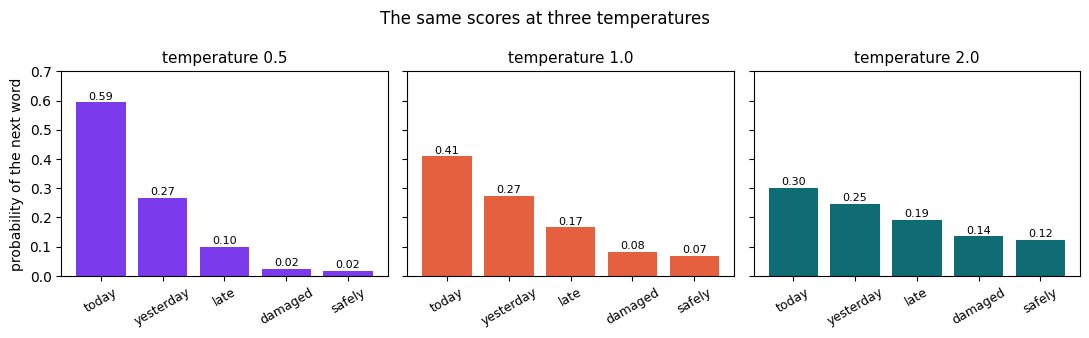

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, t, color in zip(axes, TEMPERATURES, ["#7c3aed", "#e5603f", "#0f6b74"]):
    probs = softmax(SCORES, temperature=t)
    ax.bar(CANDIDATES, probs, color=color)
    ax.set_title(f"temperature {t}", fontsize=11)
    ax.set_ylim(0, 0.7)
    ax.tick_params(axis="x", labelrotation=30, labelsize=9)
    for i, p in enumerate(probs):
        ax.text(i, p + 0.01, f"{p:.2f}", ha="center", fontsize=8)
axes[0].set_ylabel("probability of the next word")
fig.suptitle("The same scores at three temperatures", fontsize=12)
fig.tight_layout()
plt.show()

At temperature 0.5, *today* takes 0.59 of the probability and the entropy is 1.51 bits. At 1.0 its share falls to 0.41, and at 2.0 to 0.30, with the entropy rising to 2.24 bits. Entropy measures the spread in bits. A certain outcome has 0, and five equally likely words would have about 2.32.

## Sending the same request many times

The scores aren't visible, so the way to see a request's distribution is to sample it, by sending the same request many times and counting the answers. The cell sends four requests twenty times each to Claude Sonnet 5.5 at its default sampling settings, then computes each one's distribution and entropy with `empirical_distribution` and `entropy_bits`.

In [6]:
PROMPTS = {
    "random number": "Pick a random whole number from 1 to 10. Reply with the number only.",
    "fruit": "Name a fruit. Reply with one word.",
    "coffee shop name": "Suggest a one-word name for a new coffee shop. Reply with the name only.",
    "ticket category": ("Sort this support ticket into one category from billing, login, shipping or other. "
                        "Reply with the category only.\n\n"
                        "I can't log in to download the invoice for my last order."),
}
N = 20          # the same request, sent this many times
USAGE = []      # the token counts of every call, added up at the end


def answer_text(reply):
    """The text of a reply. Its content is a list of blocks, and the text blocks hold the answer."""
    return "".join(block.text for block in reply.content if block.type == "text")


samples = {}
for name, prompt in PROMPTS.items():
    answers = []
    for _ in range(N):
        reply = client.messages.create(model=MODEL, max_tokens=1024,
                                       messages=[{"role": "user", "content": prompt}])
        USAGE.append(reply.usage)
        answers.append(answer_text(reply))
    samples[name] = answers

for name, answers in samples.items():
    dist = empirical_distribution(answers)
    shares = ", ".join(f"{answer} {share:.0%}" for answer, share in dist.items())
    print(f"{name:17} {shares}   entropy {entropy_bits(dist):.2f} bits")

random number     7 100%   entropy 0.00 bits
fruit             apple 75%, mango 25%   entropy 0.81 bits
coffee shop name  ember 100%   entropy 0.00 bits
ticket category   login 100%   entropy 0.00 bits


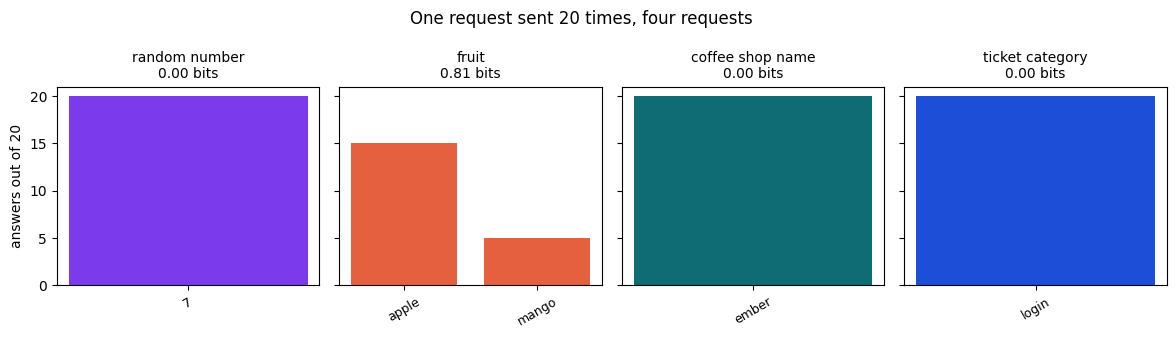

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
for ax, (name, answers), color in zip(axes, samples.items(), ["#7c3aed", "#e5603f", "#0f6b74", "#1d4ed8"]):
    dist = empirical_distribution(answers)
    ax.bar(list(dist), [share * N for share in dist.values()], color=color)
    ax.set_title(f"{name}\n{entropy_bits(dist):.2f} bits", fontsize=10)
    ax.tick_params(axis="x", labelrotation=30, labelsize=9)
axes[0].set_ylabel(f"answers out of {N}")
fig.suptitle(f"One request sent {N} times, four requests", fontsize=12)
fig.tight_layout()
plt.show()

Three of the four requests came back the same twenty times out of twenty. The random number was 7 every time, the coffee shop was always *Ember*, and the ticket about an invoice behind a login was always `login`. Only the fruit split, apple fifteen times and mango five, an entropy of 0.81 bits. A model asked for a random number returns the number its distribution favors, so randomness belongs in code such as `random.randint`. Twenty identical answers also say little about the twenty-first call, because a fixed answer and one with a rare alternative look the same in a small sample. The first book's [Probability by Simulation](https://johnfisher-ai.github.io/Statistics-Data-Science-AI-Visual-Book/chapters/probability-by-simulation.html) covers estimating a distribution from repeated draws.

## What the sampling cost

Every call is billed, so sampling a request multiplies its cost by the number of samples.

In [8]:
# Claude Sonnet 5.5's prices per million tokens, as of November 2026. Check the current ones before relying on them.
PRICE_IN, PRICE_OUT = 2.00, 10.00
tokens_in = sum(u.input_tokens for u in USAGE)
tokens_out = sum(u.output_tokens for u in USAGE)
thinking = sum(u.output_tokens_details.thinking_tokens for u in USAGE)
print(f"{len(USAGE)} calls, {tokens_in} input tokens, {tokens_out} output tokens, {thinking} of them thinking")
print(f"about {tokens_in / 1e6 * PRICE_IN + tokens_out / 1e6 * PRICE_OUT:.4f} dollars at those prices")

80 calls, 2880 input tokens, 351 output tokens, 31 of them thinking
about 0.0093 dollars at those prices


The 80 calls read 2,880 input tokens and wrote 351, about 0.0093 dollars at Claude Sonnet 5.5's prices as of November 2026. All but one call wrote 3 or 5 output tokens. One of the twenty ticket calls wrote 34, 31 of them thinking, for the same one-word answer, so a request's cost varies from call to call as well as its answer.

## In brief

- A model generates text one token at a time, sampling each token from a probability distribution over its vocabulary.
- Token counts follow the vocabulary and differ from word counts. *billing* matched *cat*, and *unbelievably* took three more tokens.
- Temperature reshapes the distribution before sampling. As of November 2026 the API no longer accepts it, so each request samples at the model's defaults.
- Sending one request many times is how you see its distribution from outside. Three of four requests returned one answer twenty times, and the fruit split 15 to 5.
- The arithmetic in this notebook comes from `sampling.py`, which Claude Code generated from a spec and tests.

---
<div style="text-align:center;color:#666f8e;font-size:12px;margin-top:10px">Building AI with AI: A Visual Handbook · © 2026 John Fisher · text CC BY 4.0, code MIT</div>